# Ablation Study — What Each Part of the System Contributes

**Project:** Explainable Inhibitor Risk Classification for Haemophilia A Using Fused Genomic–Clinical Data
**Project ID:** PW26_DN_03 · PES University · Notebook 04

An ablation study removes one component at a time and measures how much performance drops. Three questions:

1. **Data blocks** — does fusing genomic and clinical data beat either block alone?
2. **Feature families** — which of the five families of inputs matter (leave one family out at a time)?
3. **Models** — does the four-model ensemble beat each of its members and a linear baseline?

**Protocol (same as notebook 02):** variant-grouped `StratifiedGroupKFold`, 3 repeats × 5 folds = 15 test folds per
configuration; every configuration sees exactly the same folds. Threshold-free metrics are reported (ROC-AUC, PR-AUC,
Brier score), so no decision threshold can favour one configuration. "Folds better" counts in how many of the 15 folds
the full model beat the ablated one. Run time ≈ 25 min.

In [1]:
import os, sys, time, warnings
from pathlib import Path
os.environ["TQDM_DISABLE"] = "1"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pipeline.py").exists())
sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from src.pipeline import InhibitorEnsemble, build_features, features_v1, base_columns, load_reports
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "tables"

df, _ = load_reports()
num, cat = build_features(df)
num1, cat1 = features_v1(base_columns(df))
y = df["y"].astype(int).to_numpy(); groups = df["variant_key"].to_numpy(dtype=object)
FAMILY = {
    "Clinical phenotype": ["log_fviii_activity", "log_fviii_antigen", "severity", "severity_ordinal", "crm_type",
                           "fviii_activity_kind", "fviii_antigen_kind", "fviii_below_1", "fviii_measured"],
    "Genotype x clinical": ["null_x_severe", "missense_x_mild", "effect_x_severity"],
    "Variant class": ["mut_type", "effect", "is_null_variant", "is_large_deletion", "log_n_bp", "truncation_fraction",
                      "nmd_escape", "aa_alt_class", "location"],
    "Position / protein structure": ["cdna_position", "aa_position", "exon_intron_number", "domain", "relative_pos",
                                     "is_light_chain", "epitope_distance", "log_epitope_distance", "in_epitope",
                                     "functional_site_distance", "is_exon14_B_domain", "missense_x_C_domain",
                                     "missense_x_A2", "effect_x_domain"],
    "Nucleotide / residue chemistry": ["nt_change", "aa_ref", "hydropathy_change", "charge_change", "cys_gained",
                                       "cys_lost", "arg_lost", "ref_codon_has_cpg", "is_transition", "cpg_signature",
                                       "grantham", "blosum62", "delta_volume", "delta_polarity", "aromatic_change",
                                       "pro_gly_involved"],
}
GENOMIC = FAMILY["Variant class"] + FAMILY["Position / protein structure"] + FAMILY["Nucleotide / residue chemistry"]
CLINICAL = FAMILY["Clinical phenotype"]
SPLITS = [list(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(num, y, groups)) for r in range(3)]

def run(name, cols=None, models=("LightGBM", "XGBoost", "CatBoost", "Random forest"), feats=None):
    n_, c_ = feats if feats is not None else (num, cat)
    if cols is not None:
        n_ = n_[[c for c in n_.columns if c in cols]]; c_ = c_[[c for c in c_.columns if c in cols]]
    rows = []
    for r, split in enumerate(SPLITS):
        for k, (tr, te) in enumerate(split):
            m = InhibitorEnsemble(list(models)).fit(n_.iloc[tr], c_.iloc[tr], y[tr])
            p = m.predict_proba(pd.concat([n_.iloc[te], c_.iloc[te]], axis=1))
            rows.append({"configuration": name, "repeat": r, "fold": k, "inputs": n_.shape[1] + c_.shape[1],
                         "ROC-AUC": roc_auc_score(y[te], p), "PR-AUC": average_precision_score(y[te], p),
                         "Brier": brier_score_loss(y[te], p)})
    return pd.DataFrame(rows)

def table(res, ref):
    base = res[res.configuration == ref].set_index(["repeat", "fold"])
    out = []
    for name, g in res.groupby("configuration", sort=False):
        g = g.set_index(["repeat", "fold"])
        out.append({"configuration": name, "inputs": int(g["inputs"].iloc[0]),
                    "ROC-AUC": f"{g['ROC-AUC'].mean():.3f} ± {g['ROC-AUC'].std():.3f}",
                    "PR-AUC": f"{g['PR-AUC'].mean():.3f} ± {g['PR-AUC'].std():.3f}",
                    "Brier": f"{g['Brier'].mean():.4f}",
                    "Δ ROC-AUC vs full": f"{g['ROC-AUC'].mean() - base['ROC-AUC'].mean():+.3f}",
                    "Δ PR-AUC vs full": f"{g['PR-AUC'].mean() - base['PR-AUC'].mean():+.3f}",
                    "full model better (of 15 folds)": "—" if name == ref else int((base["ROC-AUC"] > g["ROC-AUC"]).sum())})
    return pd.DataFrame(out).set_index("configuration")
T0 = time.time()
print(f"{len(y):,} reports | {y.sum()} with inhibitor | {len(set(groups)):,} variant groups | 15 grouped test folds per configuration")

4,962 reports | 836 with inhibitor | 2,474 variant groups | 15 grouped test folds per configuration


## 1. Data blocks — genomic vs clinical vs fused

The title of the project claims that *fusing* genomic and clinical data helps. This is the direct test: the same
ensemble trained on each block alone and on both together.

In [2]:
t = time.time()
FULL = "Fused: genomic + clinical + interactions (final)"
blocks = pd.concat([
    run(FULL),
    run("Genomic only (variant class, position, chemistry)", cols=GENOMIC),
    run("Clinical only (severity, FVIII activity/antigen, CRM)", cols=CLINICAL),
    run("Genomic + clinical, no interaction features", cols=GENOMIC + CLINICAL),
    run("Report's original feature set (v1, 24 inputs)", feats=(num1, cat1)),
], ignore_index=True)
tab_blocks = table(blocks, FULL)
tab_blocks.to_csv(TAB / "ablation_data_blocks.csv")
display(tab_blocks)
print(f"{(time.time() - t) / 60:.1f} min")

,inputs,ROC-AUC,PR-AUC,Brier,Δ ROC-AUC vs full,Δ PR-AUC vs full,full model better (of 15 folds)
configuration,,,,,,,
Fused: genomic + clinical + interactions (final),51,0.765 ± 0.039,0.455 ± 0.057,0.1173,+0.000,+0.000,—
"Genomic only (variant class, position, chemistry)",39,0.746 ± 0.041,0.436 ± 0.059,0.1201,-0.019,-0.019,15
"Clinical only (severity, FVIII activity/antigen, CRM)",9,0.695 ± 0.031,0.289 ± 0.038,0.1302,-0.070,-0.166,15
"Genomic + clinical, no interaction features",48,0.765 ± 0.039,0.458 ± 0.056,0.1171,+0.000,+0.003,7
"Report's original feature set (v1, 24 inputs)",24,0.760 ± 0.037,0.456 ± 0.057,0.1176,-0.005,+0.001,12


7.5 min


## 2. Feature families — leave one family out

In [3]:
t = time.time()
lofo = [blocks[blocks.configuration == FULL]]
for fam, cols in FAMILY.items():
    keep = [c for c in list(num.columns) + list(cat.columns) if c not in cols]
    lofo.append(run(f"without {fam} ({len(cols)} inputs)", cols=keep))
lofo = pd.concat(lofo, ignore_index=True)
tab_lofo = table(lofo, FULL)
tab_lofo.to_csv(TAB / "ablation_leave_one_family_out.csv")
display(tab_lofo)
print(f"{(time.time() - t) / 60:.1f} min")

,inputs,ROC-AUC,PR-AUC,Brier,Δ ROC-AUC vs full,Δ PR-AUC vs full,full model better (of 15 folds)
configuration,,,,,,,
Fused: genomic + clinical + interactions (final),51,0.765 ± 0.039,0.455 ± 0.057,0.1173,+0.000,+0.000,—
without Clinical phenotype (9 inputs),42,0.751 ± 0.041,0.439 ± 0.062,0.1195,-0.014,-0.015,15
without Genotype x clinical (3 inputs),48,0.765 ± 0.039,0.458 ± 0.056,0.1171,+0.000,+0.003,7
without Variant class (9 inputs),42,0.766 ± 0.038,0.452 ± 0.056,0.1175,+0.001,-0.002,7
without Position / protein structure (14 inputs),37,0.737 ± 0.040,0.404 ± 0.062,0.1223,-0.028,-0.051,15
without Nucleotide / residue chemistry (16 inputs),35,0.769 ± 0.034,0.453 ± 0.058,0.1176,+0.004,-0.002,6


7.6 min


## 3. Models — each ensemble member alone, a linear baseline, and the ensemble

In [4]:
t = time.time()
models = pd.concat([blocks[blocks.configuration == FULL].assign(configuration="Ensemble of 4 (final)")] + [
    run(name, models=(name,)) for name in ["LightGBM", "XGBoost", "CatBoost", "Random forest", "Logistic regression"]],
    ignore_index=True)
tab_models = table(models, "Ensemble of 4 (final)")
tab_models.to_csv(TAB / "ablation_models.csv")
display(tab_models)
print(f"{(time.time() - t) / 60:.1f} min")

,inputs,ROC-AUC,PR-AUC,Brier,Δ ROC-AUC vs full,Δ PR-AUC vs full,full model better (of 15 folds)
configuration,,,,,,,
Ensemble of 4 (final),51,0.765 ± 0.039,0.455 ± 0.057,0.1173,+0.000,+0.000,—
LightGBM,51,0.765 ± 0.039,0.453 ± 0.054,0.1177,+0.000,-0.002,8
XGBoost,51,0.763 ± 0.041,0.455 ± 0.057,0.1175,-0.001,+0.001,9
CatBoost,51,0.761 ± 0.034,0.446 ± 0.057,0.1189,-0.004,-0.009,10
Random forest,51,0.752 ± 0.036,0.437 ± 0.054,0.1200,-0.013,-0.018,14
Logistic regression,51,0.745 ± 0.036,0.438 ± 0.059,0.1201,-0.020,-0.016,15


2.2 min


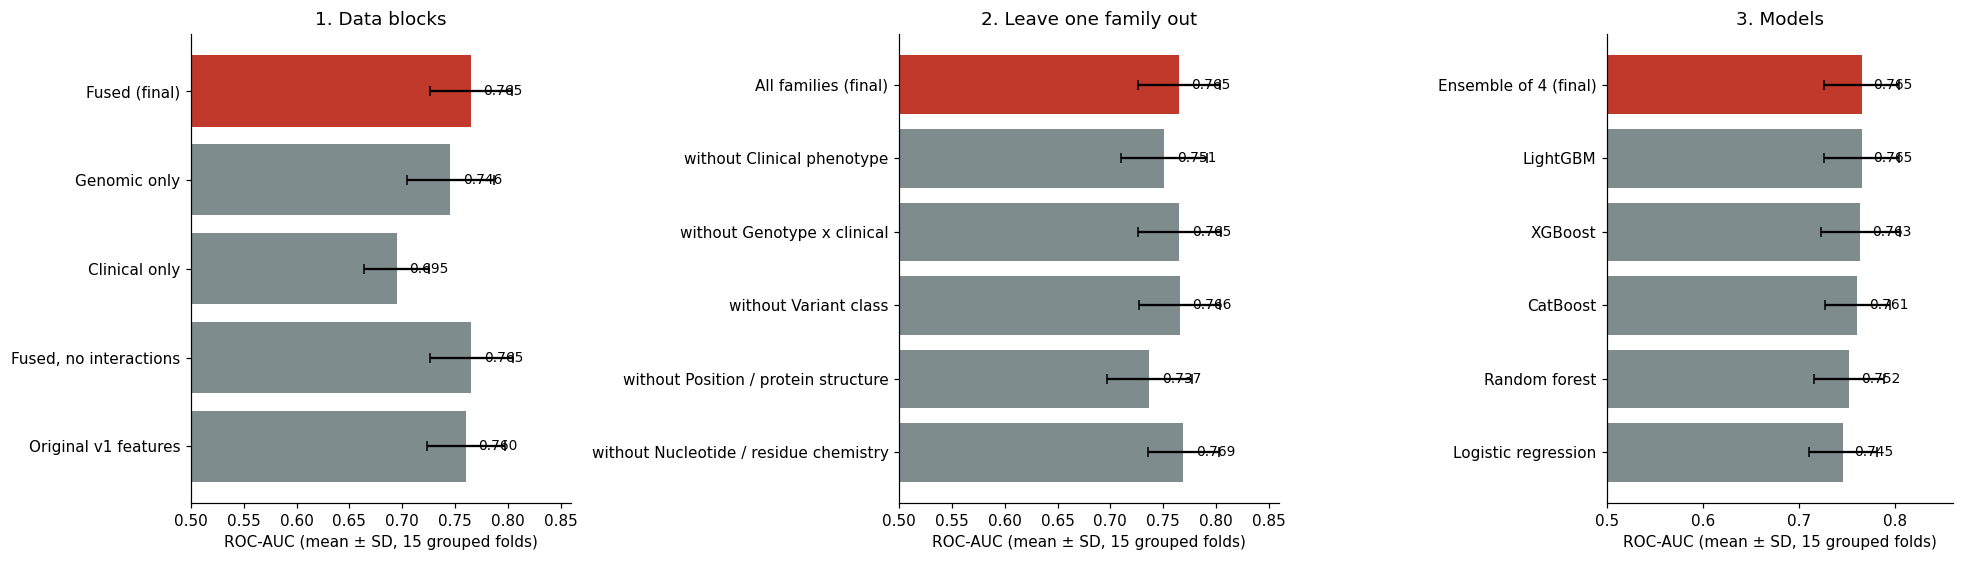

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
def bars(a, res, ref, title, short):
    g = res.groupby("configuration", sort=False)["ROC-AUC"].agg(["mean", "std"])
    labels = [short.get(i, i) for i in g.index]
    colors = ["#c0392b" if i == ref else "#7f8c8d" for i in g.index]
    a.barh(labels[::-1], g["mean"][::-1], xerr=g["std"][::-1], color=colors[::-1], capsize=3)
    for i, v in enumerate(g["mean"][::-1]):
        a.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=9)
    a.set(xlim=(0.5, 0.86), xlabel="ROC-AUC (mean ± SD, 15 grouped folds)", title=title)
bars(ax[0], blocks, FULL, "1. Data blocks", {FULL: "Fused (final)",
     "Genomic only (variant class, position, chemistry)": "Genomic only",
     "Clinical only (severity, FVIII activity/antigen, CRM)": "Clinical only",
     "Genomic + clinical, no interaction features": "Fused, no interactions",
     "Report's original feature set (v1, 24 inputs)": "Original v1 features"})
bars(ax[1], lofo, FULL, "2. Leave one family out", {FULL: "All families (final)",
     **{f"without {f} ({len(c)} inputs)": f"without {f}" for f, c in FAMILY.items()}})
bars(ax[2], models, "Ensemble of 4 (final)", "3. Models", {})
plt.tight_layout(); plt.savefig(FIG / "10_ablation_study.png", dpi=150, bbox_inches="tight"); plt.show()

In [6]:
g = lambda res, name: res[res.configuration == name]["ROC-AUC"].mean()
gp = lambda res, name: res[res.configuration == name]["PR-AUC"].mean()
full, gen, cli = g(blocks, FULL), g(blocks, "Genomic only (variant class, position, chemistry)"), \
    g(blocks, "Clinical only (severity, FVIII activity/antigen, CRM)")
drops = {f: full - g(lofo, f"without {f} ({len(c)} inputs)") for f, c in FAMILY.items()}
worst = max(drops, key=drops.get)
best_single = max(["LightGBM", "XGBoost", "CatBoost", "Random forest"], key=lambda n: g(models, n))
display(Markdown(f'''
### Summary

* **Fusion helps.** Genomic data alone reach ROC-AUC {gen:.3f}, clinical data alone {cli:.3f}; fused, the same ensemble
  reaches **{full:.3f}** (PR-AUC {gp(blocks, FULL):.3f} vs {gp(blocks, "Genomic only (variant class, position, chemistry)"):.3f} genomic-only and
  {gp(blocks, "Clinical only (severity, FVIII activity/antigen, CRM)"):.3f} clinical-only). Each block carries information the other lacks.
* **The biology features help.** The report's original 24-input feature set scores
  {g(blocks, "Report's original feature set (v1, 24 inputs)"):.3f} with the same ensemble; the final 51-input set {full:.3f}.
* **Most important family:** removing *{worst}* costs the most ({drops[worst]:+.3f} AUC). Families whose removal
  costs almost nothing overlap with others (e.g. position and chemistry both describe where and how the protein changes).
* **Models:** the best single member is {best_single} ({g(models, best_single):.3f}); the ensemble scores {full:.3f}
  and logistic regression {g(models, "Logistic regression"):.3f}. All tree models sit within a few thousandths of each
  other — consistent with notebook 02's finding that the limit is the information in the data, not the algorithm.

Total run time: {(time.time() - T0) / 60:.1f} min.
'''))


### Summary

* **Fusion helps.** Genomic data alone reach ROC-AUC 0.746, clinical data alone 0.695; fused, the same ensemble
  reaches **0.765** (PR-AUC 0.455 vs 0.436 genomic-only and
  0.289 clinical-only). Each block carries information the other lacks.
* **The biology features help.** The report's original 24-input feature set scores
  0.760 with the same ensemble; the final 51-input set 0.765.
* **Most important family:** removing *Position / protein structure* costs the most (+0.028 AUC). Families whose removal
  costs almost nothing overlap with others (e.g. position and chemistry both describe where and how the protein changes).
* **Models:** the best single member is LightGBM (0.765); the ensemble scores 0.765
  and logistic regression 0.745. All tree models sit within a few thousandths of each
  other — consistent with notebook 02's finding that the limit is the information in the data, not the algorithm.

Total run time: 17.3 min.
